# COSC 4V88 Project 5 – Part A, Step 2: Explanation fidelity and fairness audit

**Owner:** Shuo Gao (Part A)

Step 1 produced the fixed data split and the two models. This notebook answers two Part A questions:

1. **Fidelity:** do the SHAP and LIME explanations actually reflect what each model does?
2. **Fairness audit:** how do the models' errors differ across sex, age and education groups, with uncertainty?

**Input:** `part_a_outputs.zip` from Step 1 (upload it to Colab's file panel first).
**Output:** `part_a_step2_outputs.zip`, downloaded automatically at the end.

It uses the same clients, background data and explainer settings as Part B, so the results line up.

**v2 (Nov 23):** explains 500 clients (200 validation + 300 test, the same as Part B v2) instead of 100, so Part C can choose its flag threshold on validation clients and evaluate on test clients. Fidelity summaries are reported for the test clients. The fairness audit adds marital status and 95% intervals for the gaps themselves.

Run with **Runtime → Run all**. It takes about 5 minutes.

In [1]:
!pip -q install shap lime xgboost "scikit-learn==1.6.1"

In [2]:
import json, os, zipfile, shutil, platform, random, warnings
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn, xgboost, shap, lime
from lime.lime_tabular import LimeTabularExplainer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")

IN = "part_a_outputs"
if not os.path.exists(IN):
    with zipfile.ZipFile(IN + ".zip") as z:
        z.extractall(IN)

with open(f"{IN}/results/config.json") as f:
    config = json.load(f)
SEED = config["seed"]
random.seed(SEED); np.random.seed(SEED)
FEATURES, TARGET, THRESHOLDS = config["features"], config["target"], config["thresholds_chosen_on_validation"]

train_df = pd.read_csv(f"{IN}/data/train.csv")
val_df = pd.read_csv(f"{IN}/data/val.csv")
test_df = pd.read_csv(f"{IN}/data/test.csv")
models = {
    "LogisticRegression": joblib.load(f"{IN}/models/logistic_regression.joblib"),
    "XGBoost": joblib.load(f"{IN}/models/xgboost.joblib"),
}
predict = {name: (lambda X, m=m: m.predict_proba(pd.DataFrame(X, columns=FEATURES))[:, 1]) for name, m in models.items()}

OUT = "part_a_step2_outputs"
for sub in ["results", "figures"]:
    os.makedirs(f"{OUT}/{sub}", exist_ok=True)

VERSIONS = {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
            "xgboost": xgboost.__version__, "shap": shap.__version__, "lime": version("lime")}
print(VERSIONS)
print(len(FEATURES), "features; thresholds:", THRESHOLDS)

{'python': '3.13.18', 'scikit-learn': '1.6.1', 'xgboost': '3.4.1', 'shap': '0.54.1', 'lime': '0.2.0.1'}
19 features; thresholds: {'LogisticRegression': 0.25, 'XGBoost': 0.26}


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Clients to explain and background data

To keep Parts A, B and C consistent, this notebook uses **exactly the same clients and settings as Part B** (`Part_B_explanations.ipynb`):

- **500 clients**: 300 test clients (the original 100 drawn with seed 42, plus 200 more drawn with seed 43) and 200 validation clients (seed 42). Each has a `split` column (`val` or `test`).
- **SHAP background: 150 training clients**, drawn with `np.random.seed(42); np.random.choice(len(train), 150, replace=False)`.

Both are saved with their row positions **and** client IDs, so everyone can refer to the same client.

In [3]:
N_BACKGROUND = 150

# Same sample definition as Part B v2
def build_explain_sample(val_df, test_df, seed=SEED):
    np.random.seed(seed)
    test_pos_orig = np.random.choice(len(test_df), 100, replace=False)
    rest = np.setdiff1d(np.arange(len(test_df)), test_pos_orig)
    test_pos_new = np.random.RandomState(seed + 1).choice(rest, 200, replace=False)
    np.random.seed(seed)
    val_pos = np.random.choice(len(val_df), 200, replace=False)
    parts = []
    for split, df, pos in [("val", val_df, val_pos), ("test", test_df, np.concatenate([test_pos_orig, test_pos_new]))]:
        p = df.iloc[pos].copy()
        p.insert(0, "row_index", pos)
        p.insert(0, "split", split)
        parts.append(p)
    return pd.concat(parts, ignore_index=True)

np.random.seed(SEED)
background_pos = np.random.choice(len(train_df), N_BACKGROUND, replace=False)
explain_df = build_explain_sample(val_df, test_df)
N_EXPLAIN = len(explain_df)
background_df = train_df.iloc[background_pos].reset_index(drop=True)
background_df.insert(0, "train_row_index", background_pos)

X_explain = explain_df[FEATURES].values.astype(float)
X_bg = background_df[FEATURES].values.astype(float)
X_train = train_df[FEATURES].values.astype(float)

explain_df[["split", "row_index", "ID", TARGET]].to_csv(f"{OUT}/results/explain_sample.csv", index=False)
background_df[["train_row_index", "ID"]].to_csv(f"{OUT}/results/shap_background_ids.csv", index=False)
print(explain_df.groupby("split")[TARGET].agg(["count", "sum"]).rename(columns={"count": "clients", "sum": "defaulters"}))
print(f"Background = {len(background_df)} training clients")

       clients  defaulters
split                     
test       300          69
val        200          43
Background = 150 training clients


## 2. SHAP explanations

Same settings as Part B. SHAP values are in **log-odds** units:

- **Logistic Regression:** `LinearExplainer` on the scaled features (the pipeline's scaler applied first), with the scaled background.
- **XGBoost:** `TreeExplainer` with `model_output="raw"` (log-odds) and the same 150-client background.

SHAP's efficiency property says: base value + sum of contributions = the model's output in log-odds. Section 4 checks this. LIME (Section 3) works in probability units, so the deletion test below compares the two methods by the **ranking** of features, measuring the effect in probability.

In [4]:
shap_vals, shap_base = {}, {}

lr_pipe = models["LogisticRegression"]
lr_scaler, lr_clf = lr_pipe.named_steps["scaler"], lr_pipe.named_steps["clf"]
bg_frame, ex_frame = background_df[FEATURES], explain_df[FEATURES]

lin_exp = shap.LinearExplainer(lr_clf, lr_scaler.transform(bg_frame))
shap_vals["LogisticRegression"] = lin_exp.shap_values(lr_scaler.transform(ex_frame))
shap_base["LogisticRegression"] = np.full(len(X_explain), float(np.ravel(lin_exp.expected_value)[0]))

tree_exp = shap.TreeExplainer(models["XGBoost"], bg_frame, model_output="raw")
shap_vals["XGBoost"] = tree_exp.shap_values(ex_frame)
shap_base["XGBoost"] = np.full(len(X_explain), float(np.ravel(tree_exp.expected_value)[0]))

def log_odds(p):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return np.log(p / (1 - p))

for name, v in shap_vals.items():
    pd.DataFrame(v, columns=FEATURES).assign(ID=explain_df["ID"], split=explain_df["split"]).to_csv(f"{OUT}/results/shap_values_{name}.csv", index=False)
    print(name, v.shape)

Background dataset has 150 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=150 when initializing the masker.


Background dataset has 150 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=150 when initializing the masker.


LogisticRegression (500, 19)
XGBoost (500, 19)


## 3. LIME explanations

LIME fits a simple weighted linear model around each client. Same settings as Part B's main explainer: `PAY_1`–`PAY_6` treated as categorical, the other features discretised into quartiles (LIME's default), 5,000 perturbed samples (LIME's default), all 19 features kept. The random state is reset to 42 for every client, so each client's explanation is exactly the one Part B uses for its agreement analysis.

With discretisation, each LIME feature means "this client's value falls in the same bin as the explained client". We keep the full local model (intercept and all weights) so we can test it on new points in Section 4.

In [5]:
LIME_SAMPLES = 5000
CATEGORICAL_IDX = [i for i, f in enumerate(FEATURES) if f.startswith("PAY_") and not f.startswith("PAY_AMT")]
lime_explainer = LimeTabularExplainer(
    X_train, feature_names=FEATURES, categorical_features=CATEGORICAL_IDX,
    class_names=["No Default", "Default"], mode="classification",
    discretize_continuous=True, discretizer="quartile", random_state=SEED)

def proba_2col(f):
    return lambda X: np.column_stack([1 - f(X), f(X)])

lime_w, lime_intercept, lime_r2 = {}, {}, {}
for name in models:
    W = np.zeros((len(X_explain), len(FEATURES))); b = np.zeros(len(X_explain)); r2 = np.zeros(len(X_explain))
    for i, x in enumerate(X_explain):
        lime_explainer.random_state = np.random.RandomState(SEED)
        e = lime_explainer.explain_instance(x, proba_2col(predict[name]), labels=(1,),
                                            num_features=len(FEATURES), num_samples=LIME_SAMPLES)
        for j, w in e.as_map()[1]:
            W[i, j] = w
        b[i], r2[i] = e.intercept[1], e.score
    lime_w[name], lime_intercept[name], lime_r2[name] = W, b, r2
    pd.DataFrame(W, columns=FEATURES).assign(ID=explain_df["ID"], split=explain_df["split"], intercept=b, local_r2=r2) \
        .to_csv(f"{OUT}/results/lime_weights_{name}.csv", index=False)
    print(name, "done")

LogisticRegression done


XGBoost done


## 4. Fidelity: do the explanations reflect the model?

Predictive accuracy and explanation fidelity measure different things. We use three checks.

**4a. SHAP efficiency.** Base value + sum of SHAP contributions should equal the model's output in log-odds.

**4b. LIME local fit on new, real neighbours (weighted MSE).** LIME's surrogate is fitted on synthetic samples, so we test it on points it did not see: the 200 *real* training clients closest to each explained client (in standardised feature space). Weighted error:

`WMSE = Σ w (f(z) − g(z))² / Σ w`, with `w = exp(−d² / σ²)` and σ = 0.75·√(number of features), LIME's default kernel width.

To make the number readable, we divide it by the WMSE of a trivial "surrogate" that predicts the same probability as at the explained client for every neighbour. **Relative WMSE below 1 means LIME's local model explains more than "nothing changes"; above 1 means it is worse than doing nothing.**

**4c. Deletion test (both methods, comparable).** If an explanation is faithful, replacing the features it ranks as most important should change the prediction more than replacing random features. For k = 1, 3, 5 we replace the top-k features with values from the background clients and measure the average absolute change in predicted probability, against the same change for k random features (5 random draws).

In [6]:
# 4a. SHAP efficiency
eff_rows = []
for name in models:
    f_x = log_odds(predict[name](X_explain))
    err = np.abs(shap_base[name] + shap_vals[name].sum(axis=1) - f_x)
    eff_rows.append({"model": name, "mean_abs_error": err.mean(), "max_abs_error": err.max()})
efficiency = pd.DataFrame(eff_rows)
efficiency

,model,mean_abs_error,max_abs_error
0,LogisticRegression,2.175465e-16,1.554312e-15
1,XGBoost,4.202066e-07,1.719853e-06


In [7]:
# 4b. LIME weighted error on real neighbours
K_NEIGHBOURS = 200
scaler = StandardScaler().fit(X_train)
Z_train = scaler.transform(X_train)
nn = NearestNeighbors(n_neighbors=K_NEIGHBOURS).fit(Z_train)
dist, idx = nn.kneighbors(scaler.transform(X_explain))
sigma = 0.75 * np.sqrt(len(FEATURES))
train_bins = lime_explainer.discretizer.discretize(X_train)
explain_bins = lime_explainer.discretizer.discretize(X_explain)

wmse_rows = []
for name in models:
    f_train = predict[name](X_train)
    f_x = predict[name](X_explain)
    for i in range(len(X_explain)):
        nb = idx[i]
        w = np.exp(-dist[i] ** 2 / sigma ** 2)
        same_bin = (train_bins[nb] == explain_bins[i]).astype(float)
        g = lime_intercept[name][i] + same_bin @ lime_w[name][i]
        f = f_train[nb]
        wmse = np.sum(w * (f - g) ** 2) / np.sum(w)
        wmse_const = np.sum(w * (f - f_x[i]) ** 2) / np.sum(w)
        wmse_rows.append({"ID": explain_df.loc[i, "ID"], "split": explain_df.loc[i, "split"], "model": name, "lime_local_r2": lime_r2[name][i],
                          "lime_wmse": wmse, "const_wmse": wmse_const, "lime_relative_wmse": wmse / wmse_const})
lime_fid = pd.DataFrame(wmse_rows)
lime_fid.groupby(["split", "model"])[["lime_local_r2", "lime_wmse", "lime_relative_wmse"]].median()

lime_local_r2  lime_wmse  lime_relative_wmse
split model                                                           
test  LogisticRegression       0.133830   0.002150            4.297577
      XGBoost                  0.131931   0.006274            1.438490
val   LogisticRegression       0.131250   0.002187            4.358414
      XGBoost                  0.126859   0.005859            1.530636

In [8]:
# 4c. Deletion test
K_LIST, N_RANDOM = [1, 3, 5], 5
rng = np.random.default_rng(SEED)

def replace_change(f, x, feats):
    if len(feats) == 0:
        return 0.0
    Xr = np.repeat(x[None, :], len(X_bg), axis=0)
    Xr[:, feats] = X_bg[:, feats]
    return abs(f(x[None, :])[0] - f(Xr).mean())

attributions = {("SHAP", m): np.abs(shap_vals[m]) for m in models}
attributions.update({("LIME", m): np.abs(lime_w[m]) for m in models})

del_rows = []
for name in models:
    f = predict[name]
    for i, x in enumerate(X_explain):
        for k in K_LIST:
            rand = np.mean([replace_change(f, x, rng.choice(len(FEATURES), k, replace=False)) for _ in range(N_RANDOM)])
            row = {"ID": explain_df.loc[i, "ID"], "split": explain_df.loc[i, "split"], "model": name, "k": k, "random": rand}
            for method in ["SHAP", "LIME"]:
                top = np.argsort(-attributions[(method, name)][i])[:k]
                row[method] = replace_change(f, x, top)
            del_rows.append(row)
deletion = pd.DataFrame(del_rows)
deletion.to_csv(f"{OUT}/results/deletion_test_per_client.csv", index=False)
deletion[deletion.split == "test"].groupby(["model", "k"])[["SHAP", "LIME", "random"]].mean().round(4)

SHAP    LIME  random
model              k                        
LogisticRegression 1  0.0881  0.0853  0.0083
                   3  0.0936  0.0900  0.0236
                   5  0.1013  0.0969  0.0371
XGBoost            1  0.0746  0.0685  0.0140
                   3  0.1128  0.0980  0.0327
                   5  0.1315  0.1178  0.0481

### Fidelity summary with 95% bootstrap confidence intervals

Each value is the mean over the explained clients in each split (300 test, 200 validation), with a 95% interval from 1,000 bootstrap resamples of those clients. The report uses the test values.

In [9]:
def boot_mean(values, n_boot=1000, seed=SEED):
    v = np.asarray(values, dtype=float)
    r = np.random.default_rng(seed)
    means = [v[r.integers(0, len(v), len(v))].mean() for _ in range(n_boot)]
    return v.mean(), np.percentile(means, 2.5), np.percentile(means, 97.5)

rows = []
for split in ["test", "val"]:
  sel = (explain_df["split"] == split).values
  for name in models:
    d3 = deletion[(deletion.model == name) & (deletion.k == 3) & (deletion.split == split)]
    lf = lime_fid[(lime_fid.model == name) & (lime_fid.split == split)]
    checks = {
        "SHAP efficiency: mean |error| (log-odds)": np.abs(shap_base[name][sel] + shap_vals[name][sel].sum(axis=1) - log_odds(predict[name](X_explain[sel]))),
        "LIME local R² (own samples)": lf["lime_local_r2"],
        "LIME relative WMSE (real neighbours)": lf["lime_relative_wmse"],
        "Deletion top-3 change: SHAP": d3["SHAP"],
        "Deletion top-3 change: LIME": d3["LIME"],
        "Deletion 3 random features": d3["random"],
        "Share of clients where SHAP top-3 > random": (d3["SHAP"] > d3["random"]).astype(float),
        "Share of clients where LIME top-3 > random": (d3["LIME"] > d3["random"]).astype(float),
    }
    for metric, vals in checks.items():
        m, lo, hi = boot_mean(vals)
        rows.append({"split": split, "model": name, "metric": metric, "n_clients": int(sel.sum()), "mean": round(m, 4), "ci_low": round(lo, 4), "ci_high": round(hi, 4)})
fidelity_summary = pd.DataFrame(rows)
fidelity_summary.to_csv(f"{OUT}/results/fidelity_summary.csv", index=False)
fidelity_summary[fidelity_summary.split == "test"].pivot(index="metric", columns="model", values="mean")

model,LogisticRegression,XGBoost
metric,,
Deletion 3 random features,0.0236,0.0327
Deletion top-3 change: LIME,0.0900,0.0980
Deletion top-3 change: SHAP,0.0936,0.1128
LIME local R² (own samples),0.1467,0.1795
LIME relative WMSE (real neighbours),31.1761,4.2041
SHAP efficiency: mean |error| (log-odds),0.0000,0.0000
Share of clients where LIME top-3 > random,0.8733,0.7767
Share of clients where SHAP top-3 > random,0.9400,0.8633


In [10]:
# Per-client fidelity table for Part C's reliability flag
d3 = deletion[deletion.k == 3].rename(columns={"SHAP": "shap_deletion_top3", "LIME": "lime_deletion_top3", "random": "random_deletion_3"})
per_client = lime_fid.merge(d3.drop(columns=["k", "split"]), on=["ID", "model"])
per_client.insert(1, "row_index", per_client["ID"].map(dict(zip(explain_df["ID"], explain_df["row_index"]))))
per_client["lime_faithful_vs_random"] = per_client["lime_deletion_top3"] / per_client["random_deletion_3"].replace(0, np.nan)
per_client["shap_faithful_vs_random"] = per_client["shap_deletion_top3"] / per_client["random_deletion_3"].replace(0, np.nan)
per_client.to_csv(f"{OUT}/results/fidelity_per_client.csv", index=False)
per_client.head()

,ID,row_index,split,model,lime_local_r2,lime_wmse,const_wmse,lime_relative_wmse,random_deletion_3,shap_deletion_top3,lime_deletion_top3,lime_faithful_vs_random,shap_faithful_vs_random
0,11192,1782,val,LogisticRegression,0.159368,0.015706,0.009938,1.580434,0.027810,0.087764,0.087764,3.155807,3.155807
1,22221,3917,val,LogisticRegression,0.020124,0.000314,0.000323,0.972291,0.009032,0.017298,0.003881,0.429751,1.915258
2,25807,221,val,LogisticRegression,0.103875,0.001625,0.000113,14.395000,0.009769,0.019576,0.019576,2.003862,2.003862
3,24319,2135,val,LogisticRegression,0.164905,0.001058,0.000122,8.667379,0.034282,0.051959,0.051959,1.515618,1.515618
4,21961,5224,val,LogisticRegression,0.124021,0.068490,0.008007,8.553349,0.113048,0.510782,0.496061,4.388038,4.518257


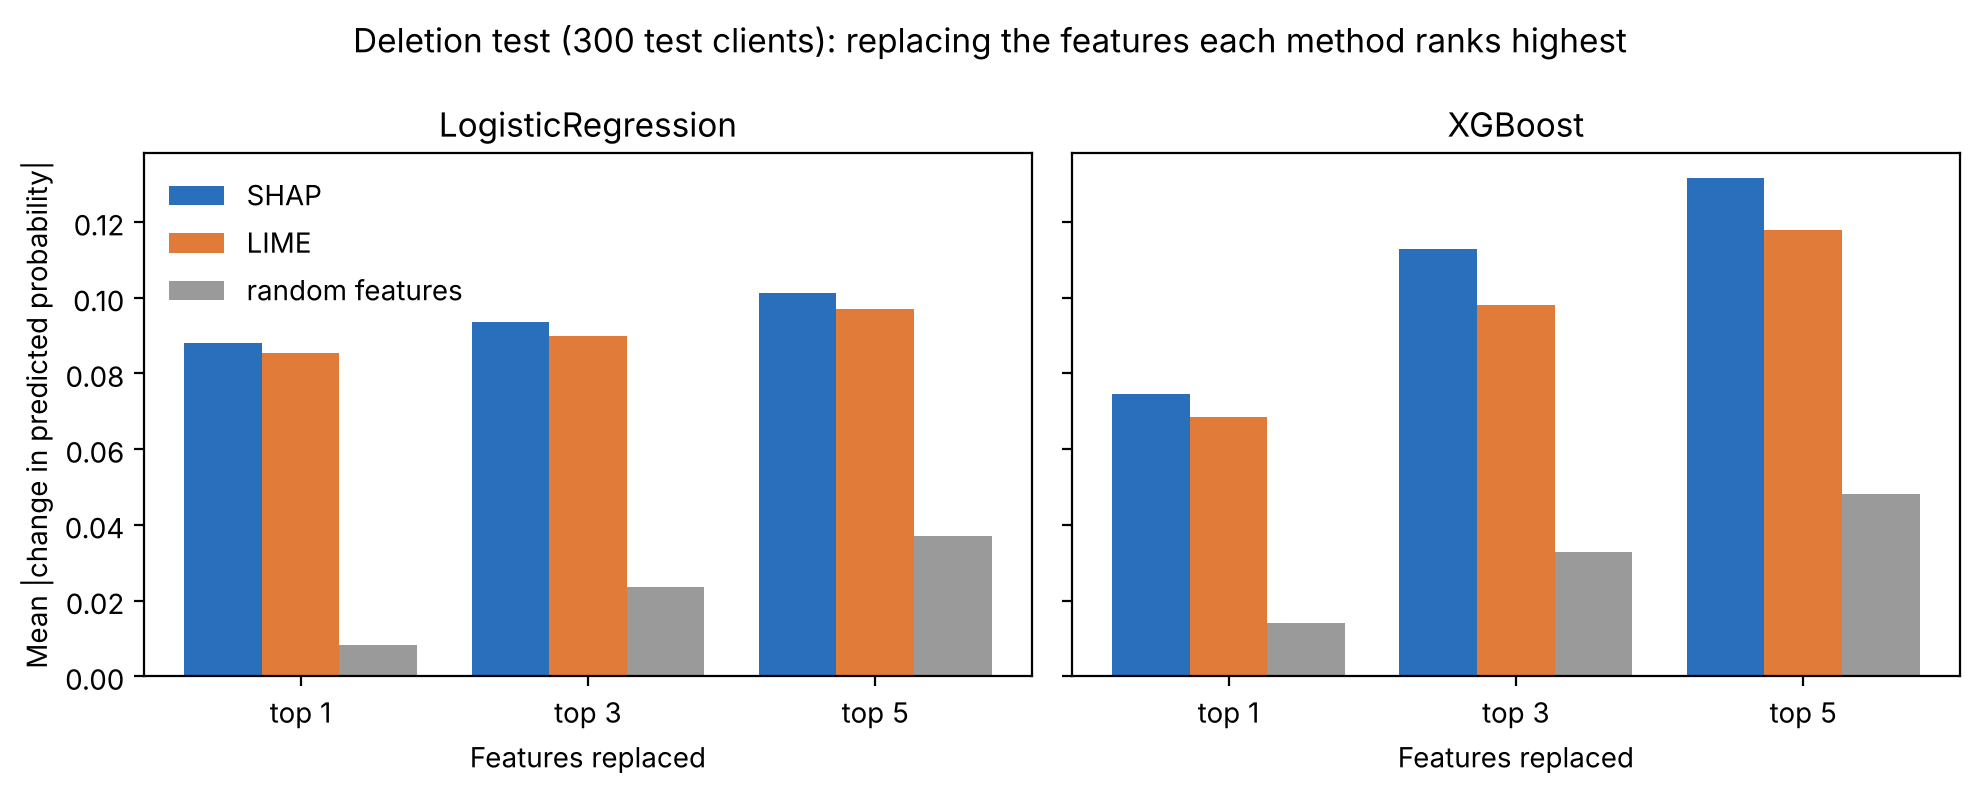

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, name in zip(axes, models):
    g = deletion[(deletion.model == name) & (deletion.split == "test")].groupby("k")[["SHAP", "LIME", "random"]].mean()
    xs = np.arange(len(g)); w = 0.27
    for j, (col, color) in enumerate([("SHAP", "#2a6fbb"), ("LIME", "#e07b39"), ("random", "#9a9a9a")]):
        ax.bar(xs + (j - 1) * w, g[col], w, label=col if col != "random" else "random features", color=color)
    ax.set_xticks(xs); ax.set_xticklabels([f"top {k}" for k in g.index])
    ax.set_title(name); ax.set_xlabel("Features replaced")
axes[0].set_ylabel("Mean |change in predicted probability|")
axes[0].legend(frameon=False)
fig.suptitle("Deletion test (300 test clients): replacing the features each method ranks highest")
plt.tight_layout()
plt.savefig(f"{OUT}/figures/deletion_test.png", dpi=200)
plt.show()

## 5. Fairness audit by group, with uncertainty

Step 1 only looked at recall. Here we report, for each group on the full test set:

- **TPR** (recall on defaulters) and **FPR** (non-defaulters wrongly flagged as risky), each with a 95% bootstrap interval
- **PPV** (precision among clients flagged as risky)
- **Mean predicted risk vs actual default rate** (calibration in the large)

Attributes: sex, age group, education and **marital status**. Gaps: **equal opportunity gap** = largest − smallest TPR; **equalized odds gap** = the larger of the TPR gap and the FPR gap. Groups with fewer than 30 defaulters are excluded from the gaps and listed as too small. **Each gap also gets its own 95% interval** (1,000 bootstrap resamples of the test set), so we can tell whether a gap is larger than sampling noise.

In [12]:
audit = test_df.copy()
audit["SEX"] = audit["SEX"].map({1: "male", 2: "female"})
audit["AGE"] = pd.cut(audit["AGE"], bins=[0, 29, 39, 49, 200], labels=["<30", "30-39", "40-49", "50+"]).astype(str)
audit["EDUCATION"] = audit["EDUCATION"].map({1: "graduate school", 2: "university", 3: "high school", 4: "others"})
audit["MARRIAGE"] = audit["MARRIAGE"].map({1: "married", 2: "single", 3: "others"})

GROUP_ORDER = {
    "SEX": ["female", "male"],
    "AGE": ["<30", "30-39", "40-49", "50+"],
    "EDUCATION": ["graduate school", "university", "high school", "others"],
    "MARRIAGE": ["married", "single", "others"],
}

def rate_ci(flags, n_boot=1000, seed=SEED):
    v = np.asarray(flags, dtype=float)
    if len(v) == 0:
        return np.nan, np.nan, np.nan
    r = np.random.default_rng(seed)
    b = [v[r.integers(0, len(v), len(v))].mean() for _ in range(n_boot)]
    return v.mean(), np.percentile(b, 2.5), np.percentile(b, 97.5)

rows = []
for name, m in models.items():
    p = m.predict_proba(test_df[FEATURES])[:, 1]
    audit["proba"], audit["pred"] = p, (p >= THRESHOLDS[name]).astype(int)
    for attr, order in GROUP_ORDER.items():
        for g in order:
            part = audit[audit[attr] == g]
            if len(part) == 0:
                continue
            pos, neg = part[part[TARGET] == 1], part[part[TARGET] == 0]
            tpr, tpr_lo, tpr_hi = rate_ci(pos["pred"])
            fpr, fpr_lo, fpr_hi = rate_ci(neg["pred"])
            flagged = part[part["pred"] == 1]
            rows.append({
                "model": name, "attribute": attr, "group": g, "n": len(part), "defaulters": len(pos),
                "TPR": round(tpr, 4), "TPR_ci": f"{tpr_lo:.3f}–{tpr_hi:.3f}",
                "FPR": round(fpr, 4), "FPR_ci": f"{fpr_lo:.3f}–{fpr_hi:.3f}",
                "PPV": round(flagged[TARGET].mean(), 4) if len(flagged) else np.nan,
                "mean_predicted_risk": round(part["proba"].mean(), 4),
                "actual_default_rate": round(part[TARGET].mean(), 4),
                "too_small": len(pos) < 30,
            })
fair = pd.DataFrame(rows)
fair.to_csv(f"{OUT}/results/subgroup_fairness.csv", index=False)

ok = fair[~fair["too_small"]]
gaps = ok.groupby(["model", "attribute"]).agg(
    TPR_gap=("TPR", lambda s: s.max() - s.min()), FPR_gap=("FPR", lambda s: s.max() - s.min())).round(4)
gaps["equalized_odds_gap"] = gaps[["TPR_gap", "FPR_gap"]].max(axis=1)
gaps = gaps.reset_index()

# 95% bootstrap intervals for the gaps themselves (groups fixed to those large enough)
rng_gap = np.random.default_rng(SEED)
y_all = test_df[TARGET].values
boot_idx = [rng_gap.integers(0, len(test_df), len(test_df)) for _ in range(1000)]
ci_rows = []
for name, m in models.items():
    pred_all = (m.predict_proba(test_df[FEATURES])[:, 1] >= THRESHOLDS[name]).astype(int)
    for attr in GROUP_ORDER:
        groups = ok[(ok.model == name) & (ok.attribute == attr)]["group"].tolist()
        g_all = audit[attr].values
        tg, fg = [], []
        for bi in boot_idx:
            yb, pb, gb = y_all[bi], pred_all[bi], g_all[bi]
            tprs = [pb[(gb == g) & (yb == 1)].mean() for g in groups]
            fprs = [pb[(gb == g) & (yb == 0)].mean() for g in groups]
            tg.append(max(tprs) - min(tprs)); fg.append(max(fprs) - min(fprs))
        ci_rows.append({"model": name, "attribute": attr,
                        "TPR_gap_ci": f"{np.percentile(tg, 2.5):.3f}–{np.percentile(tg, 97.5):.3f}",
                        "FPR_gap_ci": f"{np.percentile(fg, 2.5):.3f}–{np.percentile(fg, 97.5):.3f}"})
gaps = gaps.merge(pd.DataFrame(ci_rows), on=["model", "attribute"])
gaps.to_csv(f"{OUT}/results/fairness_gaps.csv", index=False)
display(fair)
display(gaps)

,model,attribute,group,n,defaulters,TPR,TPR_ci,FPR,FPR_ci,PPV,mean_predicted_risk,actual_default_rate,too_small
0,LogisticRegression,SEX,female,3628,755,0.5536,0.519–0.589,0.1532,0.141–0.166,0.4872,0.2169,0.2081,False
1,LogisticRegression,SEX,male,2372,572,0.5140,0.470–0.556,0.1517,0.134–0.168,0.5185,0.2257,0.2411,False
2,LogisticRegression,AGE,<30,1926,421,0.5986,0.556–0.644,0.1907,0.172–0.211,0.4675,0.2449,0.2186,False
3,LogisticRegression,AGE,30-39,2206,439,0.4875,0.440–0.538,0.1205,0.105–0.136,0.5012,0.1985,0.1990,False
4,LogisticRegression,AGE,40-49,1296,318,0.5126,0.459–0.566,0.1391,0.117–0.163,0.5452,0.2153,0.2454,False
5,LogisticRegression,AGE,50+,572,149,0.5570,0.477–0.631,0.1820,0.147–0.220,0.5188,0.2341,0.2605,False
6,LogisticRegression,EDUCATION,graduate school,2141,412,0.4709,0.420–0.519,0.1099,0.095–0.126,0.5052,0.1857,0.1924,False
7,LogisticRegression,EDUCATION,university,2775,646,0.5774,0.540–0.615,0.1705,0.155–0.188,0.5068,0.2372,0.2328,False
8,LogisticRegression,EDUCATION,high school,989,262,0.5496,0.492–0.611,0.2050,0.173–0.232,0.4915,0.2526,0.2649,False
9,LogisticRegression,EDUCATION,others,95,7,0.1429,0.000–0.429,0.1250,0.057–0.193,0.0833,0.1780,0.0737,True


,model,attribute,TPR_gap,FPR_gap,equalized_odds_gap,TPR_gap_ci,FPR_gap_ci
0,LogisticRegression,AGE,0.1111,0.0702,0.1111,0.066–0.183,0.052–0.101
1,LogisticRegression,EDUCATION,0.1065,0.0951,0.1065,0.052–0.176,0.062–0.128
2,LogisticRegression,MARRIAGE,0.0383,0.0105,0.0383,0.002–0.093,0.001–0.031
3,LogisticRegression,SEX,0.0396,0.0015,0.0396,0.003–0.091,0.001–0.024
4,XGBoost,AGE,0.0946,0.0346,0.0946,0.052–0.162,0.020–0.072
5,XGBoost,EDUCATION,0.0032,0.0866,0.0866,0.008–0.095,0.054–0.121
6,XGBoost,MARRIAGE,0.0514,0.0029,0.0514,0.005–0.105,0.000–0.025
7,XGBoost,SEX,0.0138,0.0307,0.0307,0.001–0.068,0.010–0.052


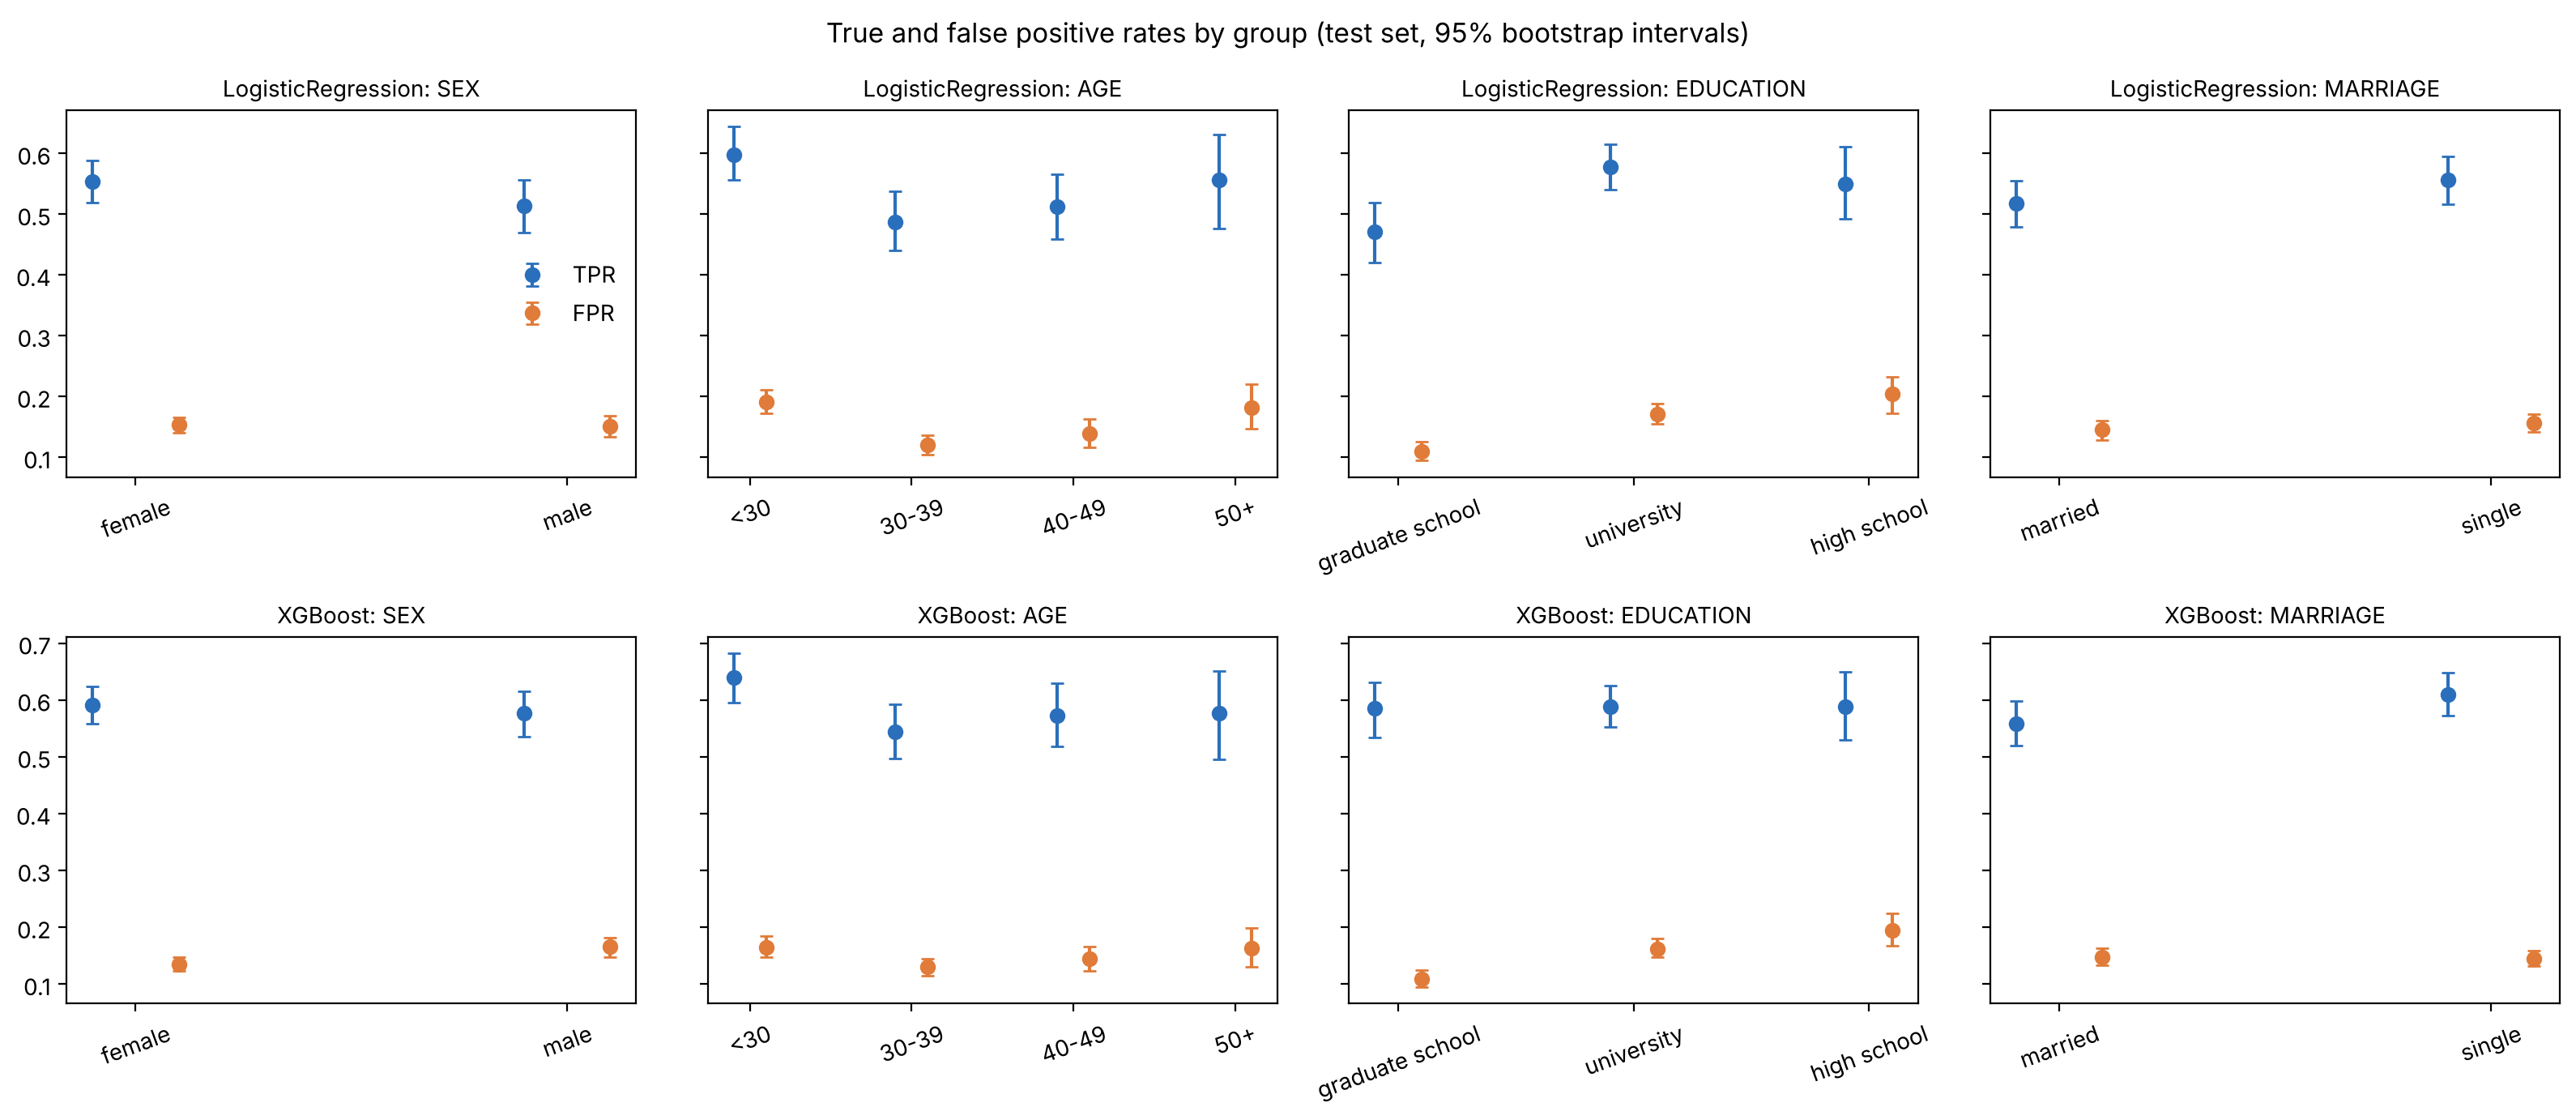

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey="row")
for r, name in enumerate(models):
    for c, attr in enumerate(["SEX", "AGE", "EDUCATION", "MARRIAGE"]):
        ax = axes[r, c]
        part = fair[(fair.model == name) & (fair.attribute == attr) & (~fair.too_small)]
        xs = np.arange(len(part))
        for j, (col, color) in enumerate([("TPR", "#2a6fbb"), ("FPR", "#e07b39")]):
            lo = part[col + "_ci"].str.split("–").str[0].astype(float)
            hi = part[col + "_ci"].str.split("–").str[1].astype(float)
            ax.errorbar(xs + (j - 0.5) * 0.2, part[col], yerr=[part[col] - lo, hi - part[col]],
                        fmt="o", capsize=3, color=color, label=col)
        ax.set_xticks(xs); ax.set_xticklabels(part["group"], rotation=20)
        ax.set_title(f"{name}: {attr}", fontsize=10)
axes[0, 0].legend(frameon=False)
fig.suptitle("True and false positive rates by group (test set, 95% bootstrap intervals)")
plt.tight_layout()
plt.savefig(f"{OUT}/figures/subgroup_tpr_fpr.png", dpi=200)
plt.show()

## 6. Save outputs

`part_a_step2_outputs.zip` contains:

- `results/explain_sample.csv`, `shap_background_ids.csv`: the 500 explained clients (with `split`) and the 150 SHAP background clients, the same as Part B
- `results/shap_values_*.csv`, `lime_weights_*.csv`: the explanations used for the fidelity tests
- `results/fidelity_summary.csv`, `fidelity_per_client.csv`, `deletion_test_per_client.csv`: fidelity results (the per-client file feeds Part C's flag)
- `results/subgroup_fairness.csv`, `fairness_gaps.csv`: the fairness audit (gaps with 95% intervals)
- `results/step2_settings.json`: every setting used here
- `figures/deletion_test.png`, `figures/subgroup_tpr_fpr.png`

In [14]:
settings = {
    "seed": SEED, "n_explain": N_EXPLAIN, "explain_sample": "200 validation + 300 test clients (same as Part B v2)", "n_background": N_BACKGROUND,
    "aligned_with": "Part_B_explanations.ipynb (same clients, background and explainer settings)",
    "shap": {"XGBoost": "TreeExplainer, model_output='raw' (log-odds), 150-client background",
             "LogisticRegression": "LinearExplainer on scaled features (log-odds), scaled 150-client background"},
    "lime": {"categorical_features": [FEATURES[i] for i in CATEGORICAL_IDX], "discretizer": "quartile",
             "num_samples": LIME_SAMPLES, "num_features": len(FEATURES), "random_state": "reset to 42 for every client"},
    "wmse": {"neighbours": f"{K_NEIGHBOURS} nearest real training clients (standardised space)", "sigma": round(sigma, 4)},
    "deletion": {"k": K_LIST, "random_draws": N_RANDOM, "replacement": "background client values"},
    "fairness": {"attributes": list(GROUP_ORDER), "min_defaulters_per_group": 30, "bootstrap": 1000},
    "versions": VERSIONS,
}
with open(f"{OUT}/results/step2_settings.json", "w") as f:
    json.dump(settings, f, indent=2)

shutil.make_archive(OUT, "zip", OUT)
print("Saved", OUT + ".zip")
try:
    from google.colab import files
    files.download(OUT + ".zip")
except ImportError:
    pass

Saved part_a_step2_outputs.zip
